In [1]:
%pip install tensorflow numpy opencv-python h5py matplotlib

In [5]:
!unzip -o /content/dataset.zip -d /content/

Archive:  /content/dataset.zip
  inflating: /content/dataset/images/image001.png  
  inflating: /content/dataset/masks/image001.png  
  inflating: /content/dataset/images/image002.png  
  inflating: /content/dataset/masks/image002.png  
  inflating: /content/dataset/images/image003.png  
  inflating: /content/dataset/masks/image003.png  
  inflating: /content/dataset/images/image004.png  
  inflating: /content/dataset/masks/image004.png  
  inflating: /content/dataset/images/image005.png  
  inflating: /content/dataset/masks/image005.png  
  inflating: /content/dataset/images/image006.png  
  inflating: /content/dataset/masks/image006.png  
  inflating: /content/dataset/images/image007.png  
  inflating: /content/dataset/masks/image007.png  
  inflating: /content/dataset/images/image008.png  
  inflating: /content/dataset/masks/image008.png  
  inflating: /content/dataset/images/image009.png  
  inflating: /content/dataset/masks/image009.png  
  inflating: /content/dataset/images/image

In [7]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import *
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np, os
import cv2

# Dataset
X = []; Y = []

image_path = r"/content/dataset/images"
mask_path = r"/content/dataset/masks"

for f in os.listdir(image_path):

    # Input image
    X.append(cv2.resize(cv2.imread(os.path.join(image_path, f)),
                        (128,128))/255.0)

    # Mask image
    Y.append(np.expand_dims(cv2.resize(
        cv2.imread(os.path.join(mask_path, f), 0),
        (128,128))/255.0, axis=-1))

# Convert list to array
X = np.array(X)
Y = np.array(Y)

# Input
i = Input((128,128,3))

# Encoder
c1 = Conv2D(32,(3,3),activation='relu',padding='same')(i)
p1 = MaxPooling2D((2,2))(c1)

# Bottleneck
c2 = Conv2D(64,(3,3),activation='relu',padding='same')(p1)

# Decoder
u1 = UpSampling2D((2,2))(c2)
m1 = concatenate([u1,c1])

# Output
o = Conv2D(1,(1,1),activation='sigmoid')(m1)

# Model
model = Model(i,o)

# Compile
model.compile(optimizer='adam',loss='binary_crossentropy',
              metrics=['accuracy'])

# Train
model.fit(X,Y,epochs=5,batch_size=2)

# Save
model.save("unet.h5")

Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9128 - loss: 0.6079 
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9132 - loss: 0.3662 
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9808 - loss: 0.1101 
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9953 - loss: 0.0258 
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9967 - loss: 0.0115 


In [8]:
from google.colab import files
files.download("unet.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
model.save("unet.h5")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 695ms/step


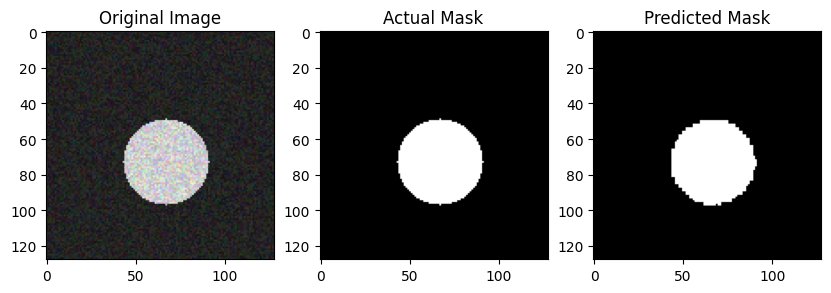

In [10]:
import matplotlib.pyplot as plt

pred = model.predict(X[0:1])

plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(X[0].astype(np.float32), cv2.COLOR_BGR2RGB))
plt.title("Original Image")

plt.subplot(1,3,2)
plt.imshow(Y[0].squeeze(), cmap="gray")
plt.title("Actual Mask")

plt.subplot(1,3,3)
plt.imshow(pred[0].squeeze() > 0.5, cmap="gray")
plt.title("Predicted Mask")

plt.show()